# Assignment 5: Problem 1
## Rock, Paper, Scissors - Teachable Machine
In this problem we will be training an model to recognize the rock, paper and scissors gestures using Teachable Machine.
The training was done using the webcam option, meanwhile the test images are stock images of the gestures.
Ideally our model will trained efficiently and properly identify the correct gestures.

Note: I had to use an older version of Keras, Python and numpy to get the Teachable Machine to work.

In [74]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from keras.layers import DepthwiseConv2D
from keras.models import load_model

In [75]:
class CustomDepthwiseConv2D(DepthwiseConv2D):
    def __init__(self, **kwargs):
        kwargs.pop("groups", None)
        super().__init__(**kwargs)


In [85]:
model = load_model("model/keras_model.h5", custom_objects={"DepthwiseConv2D" : CustomDepthwiseConv2D}, compile=False)

with open("model/labels.txt", "r") as f:
    class_names = f.readlines()

print("Model loaded successfully!")
print("Class names:", class_names)


Model loaded successfully!
Class names: ['0 Rock\n', '1 Paper\n', '2 Scissors\n']


### Rock Test

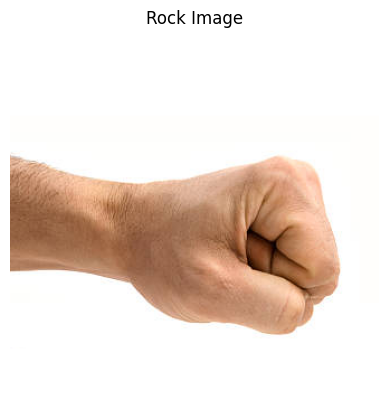

In [86]:
image_path = "images/rock_test.png"

image = Image.open(image_path).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.title("Rock Image")
plt.show()

In [87]:
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image, dtype=np.float32)
normalized_image = (image_array / 127.5) - 1
input_data = np.expand_dims(normalized_image, axis=0)
print("Image shape:", input_data.shape)

Image shape: (1, 224, 224, 3)


In [88]:
prediction = model.predict(input_data)
print("Prediction:", prediction)

1/1 [==============================] - 0s 353ms/step
Prediction: [[7.0755488e-01 2.9239878e-01 4.6341280e-05]]


In [89]:
# Find the index of the highest prediction score
predicted_index = np.argmax(prediction[0])

# Get the corresponding class name
predicted_class = class_names[predicted_index].strip()

# Get the confidence score
confidence = prediction[0][predicted_index]

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Predicted Class: 0 Rock
Confidence: 70.76%


### Paper Test

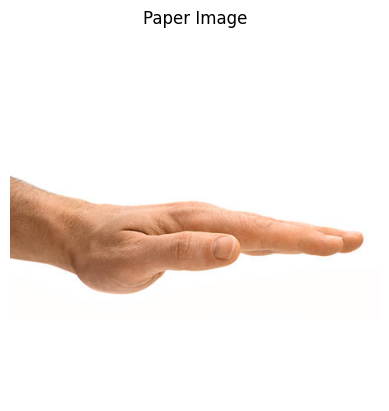

In [90]:
image_path = "images/paper_test.png"

image = Image.open(image_path).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.title("Paper Image")
plt.show()

In [91]:
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image, dtype=np.float32)
normalized_image = (image_array / 127.5) - 1
input_data = np.expand_dims(normalized_image, axis=0)
print("Image shape:", input_data.shape)

Image shape: (1, 224, 224, 3)


In [92]:
prediction = model.predict(input_data)
print("Prediction:", prediction)

1/1 [==============================] - 0s 27ms/step
Prediction: [[1.7161559e-05 9.9998271e-01 1.7528639e-07]]


In [93]:
# Find the index of the highest prediction score
predicted_index = np.argmax(prediction[0])

# Get the corresponding class name
predicted_class = class_names[predicted_index].strip()

# Get the confidence score
confidence = prediction[0][predicted_index]

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Predicted Class: 1 Paper
Confidence: 100.00%


### Scissors Test

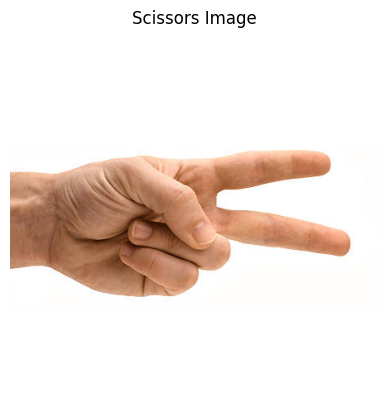

In [94]:
image_path = "images/scissors_test.png"

image = Image.open(image_path).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.title("Scissors Image")
plt.show()

In [98]:
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image, dtype=np.float32)
normalized_image = (image_array / 127.5) - 1
input_data = np.expand_dims(normalized_image, axis=0)
print("Image shape:", input_data.shape)

Image shape: (1, 224, 224, 3)


In [99]:
prediction = model.predict(input_data)
print("Prediction:", prediction)

1/1 [==============================] - 0s 21ms/step
Prediction: [[0.71653426 0.04975676 0.23370895]]


In [100]:
# Find the index of the highest prediction score
predicted_index = np.argmax(prediction[0])

# Get the corresponding class name
predicted_class = class_names[predicted_index].strip()

# Get the confidence score
confidence = prediction[0][predicted_index]

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Predicted Class: 0 Rock
Confidence: 71.65%


# Results
The Paper test successfully evaluated the test image as Paper at 100%. But the Rock test succeeded only with 70% certainty, and the Scissor test failed by incorrectly evaluating the test image as Rock with 71% certainty. This is in direct conflict with the output-test on Teachable Machine which got the gesture correct each time from the webcam.
My thinking on this test is that since the test data which trained the model was made using a webcam. There were inputs that helped determine the gestures more than the gestures alone, like arm position, rotation. Had I used more test data it is possible this test may result in a successful test all around. But since both Rock and Scissors are at 70% I think the model must be sent back to the drawing board to be retrained.